In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from bananafarm import BananaFarm

In [18]:
import importlib
import bananafarm

# Force Python to reload the updated file from disk
importlib.reload(bananafarm)
from bananafarm import BananaFarm

In [19]:
rounds = np.arange(1, 120)
starting_cash = 850
farm_purchase_round = 3

# Instantiate our Banana Farm object
my_farm = BananaFarm(purchase_round=farm_purchase_round)

def get_freeplay_multiplier(r):
    if r <= 50:
        return 1.0
    elif r <= 60:
        return 0.5
    elif r <= 85:
        return 0.2
    elif r <= 100:
        return 0.1
    else:
        return 0.05

round_income = []
for r in rounds:
    end_of_round_bonus = 100 + r
    base_pop_cash = r * 15  
    adjusted_pop_cash = base_pop_cash * get_freeplay_multiplier(r)
    total_round_cash = adjusted_pop_cash + end_of_round_bonus
    round_income.append(total_round_cash)

round_income = np.array(round_income)

cash_with_farm = []
current_cash = starting_cash
farm_owned = False

for i, r in enumerate(rounds):
    current_cash += round_income[i]

    # Purchase farm in Round 3
    if r == my_farm.purchase_round and not farm_owned:
        current_cash -= 1225  # Initial 0-0-0 cost
        farm_owned = True

    # Example Milestone Upgrade Strategy during simulation:
    if farm_owned:
        try:
            if r == 10:
                current_cash -= my_farm.upgrade(path=0, target_tier=2) # 2-0-0
            elif r == 18:
                current_cash -= my_farm.upgrade(path=0, target_tier=3) # 3-0-0 (Banana Plantation)
            elif r == 22:
                current_cash -= my_farm.upgrade(path=1, target_tier=2) # 3-2-0 (Crosspathed with Valuable Bananas)
            elif r == 35:
                current_cash -= my_farm.upgrade(path=0, target_tier=4) # 4-2-0 (Banana Research Facility)
            elif r == 55:
                current_cash -= my_farm.upgrade(path=0, target_tier=5) # 5-2-0 (Banana Central)
        except ValueError as e:
            print(f"Round {r} Upgrade Error: {e}")

        # Add income generated by the farm for this round
        current_cash += my_farm.get_round_income(r)

    cash_with_farm.append(current_cash)

cash_with_farm = np.array(cash_with_farm)
cash_without_farm = starting_cash + np.cumsum(round_income)

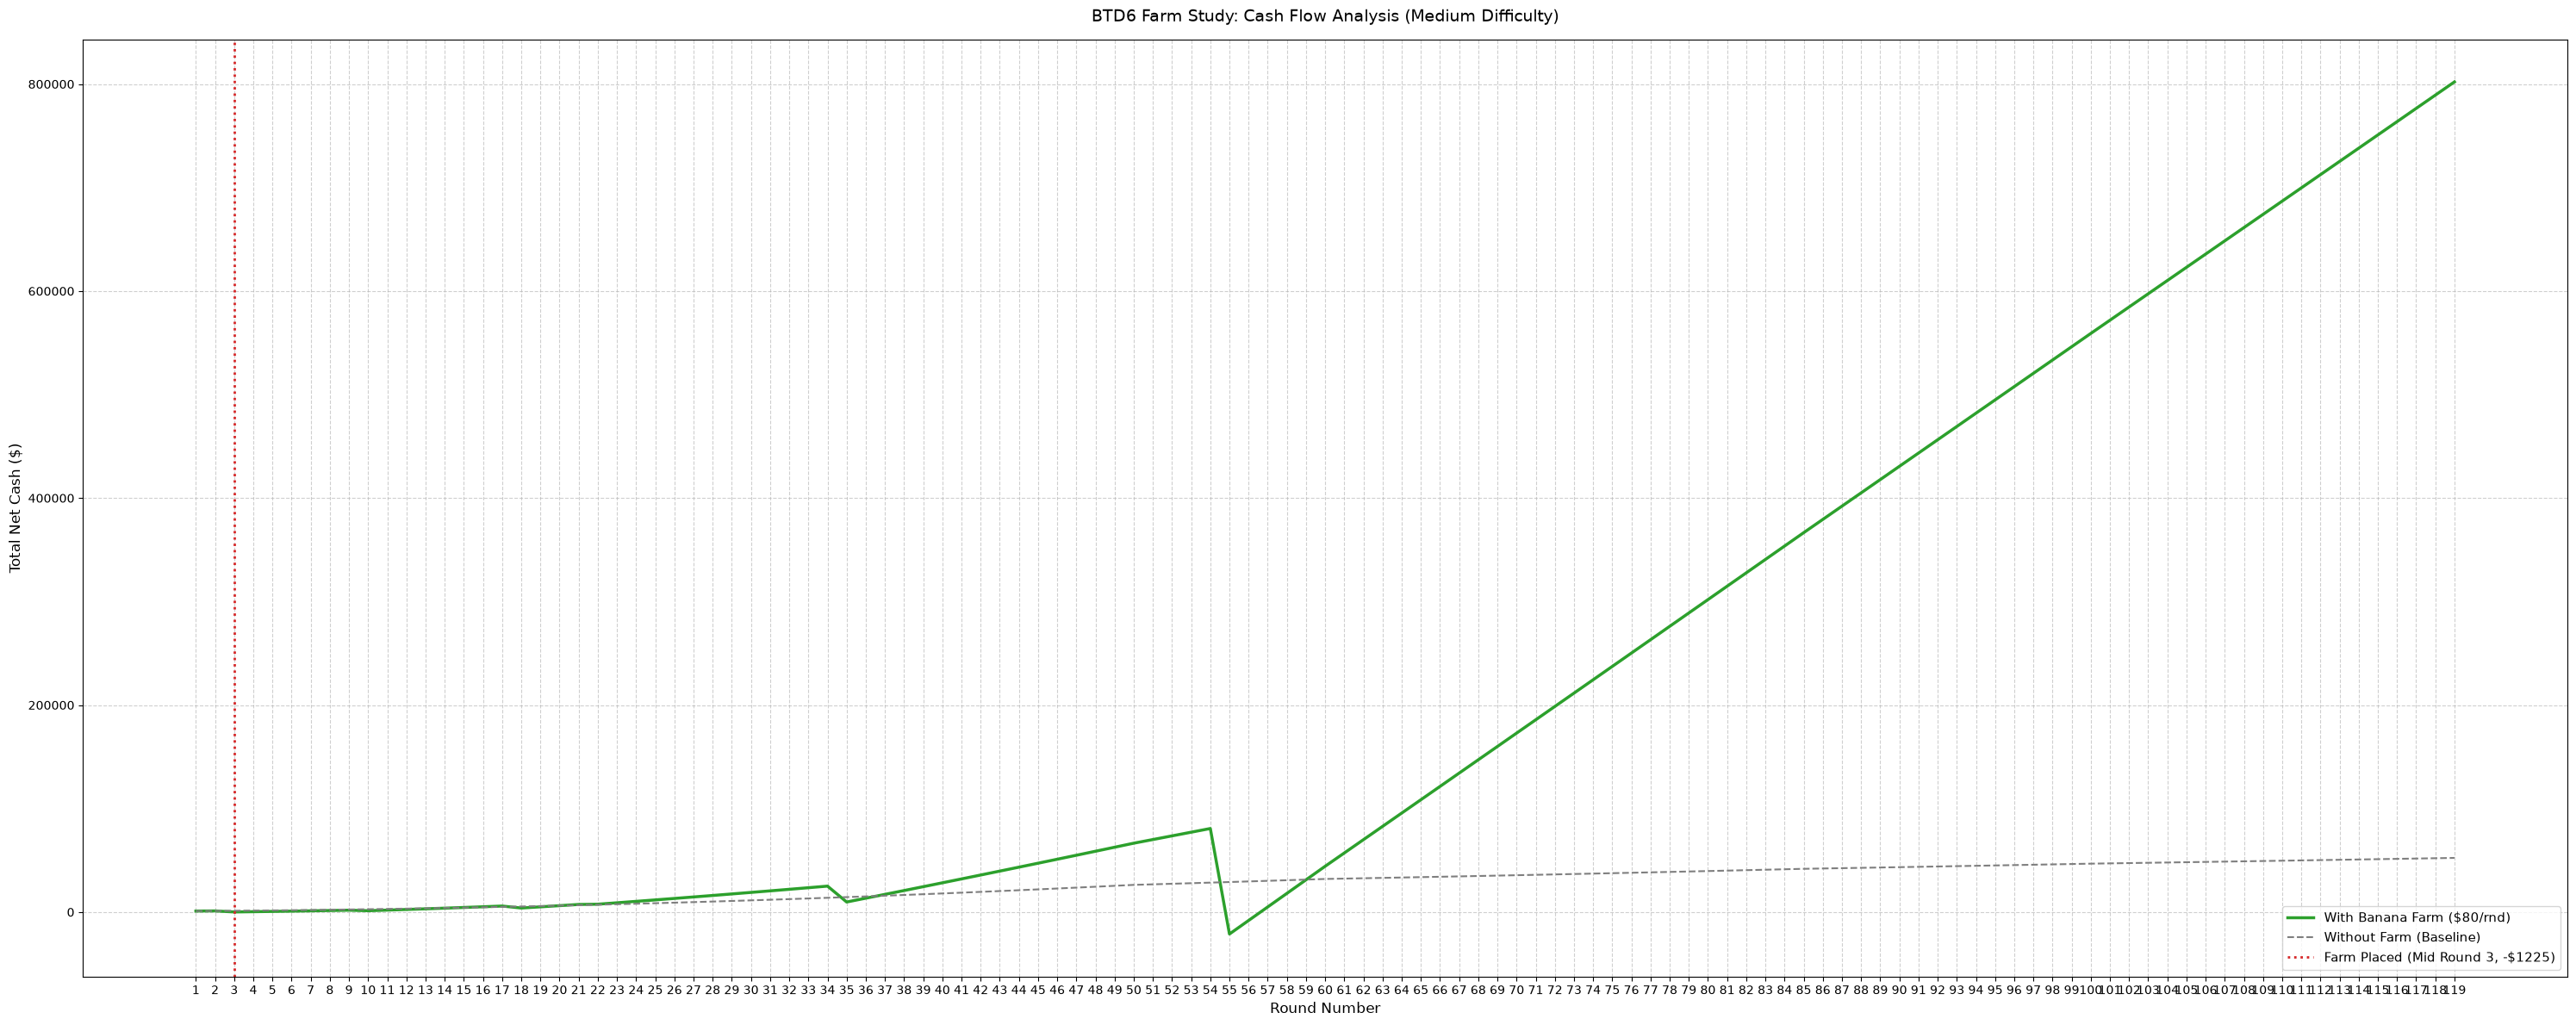

In [21]:
plt.figure(figsize=(30, 12))

plt.plot(
    rounds,
    cash_with_farm,
    color="#2ca02c",
    linewidth=2.5,
    label="With Banana Farm ($80/rnd)",
)
plt.plot(
    rounds,
    cash_without_farm,
    color="#7f7f7f",
    linestyle="--",
    linewidth=1.5,
    label="Without Farm (Baseline)",
)

# Highlight purchase event
plt.axvline(
    x=farm_purchase_round,
    color="#d62728",
    linestyle=":",
    linewidth=2,
    label=f"Farm Placed (Mid Round {farm_purchase_round}, -$1225)",
)

# Graph styling
plt.title(
    "BTD6 Farm Study: Cash Flow Analysis (Medium Difficulty)",
    fontsize=14,
    pad=15,
)
plt.xlabel("Round Number", fontsize=12)
plt.ylabel("Total Net Cash ($)", fontsize=12)
plt.xticks(rounds)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()

# Display the plot in Jupyter
plt.show()